# ARM KAZR Cloud Persistence Project: Radar Profile Features

**Alec Blevins - STA 496, Fall 2026**

## Purpose
Notebook 10, `10_analysis.ipynb` found that vertical structure (especially cloud thickness) carries most of the skill, and that cloud-fraction and age features add little for old clouds. Here, we test whether radar profile features (reflectivity, Doppler velocity, spectral width) add information about the cloud interior. 

**Rules**
- Same folds, embargo and HGB settings as notebook 10; the target is unchanged. 
- Radar features use only samples at or before time t (past-only), and we should check this. 
- Compare on validation first; test is scored once at the end, next to the cloud-state baseline. 

| Step | Question |
|---|---|
| 1. Inspect one day | What does the QC'd radar field look like? |
| 2. Column summaries | Which per-profile numbers describe the cloud interior? |
| 3. Build features | 20 s aggregates and past-only rolling windows |
| 4. Join and audit | Missingness; is it related to the target? |
| 5. Refit and compare | Do radar features add skill, overall and for old clouds? |
| 6. Importance and conclusion | Which features help; what do we freeze into `src/features.py`? |




## 1. Imports & Day One Load
Here, we pick a day with a real cloud, 2024-06-15. 

In [1]:
###################
##Library Imports##
###################

from pathlib import Path
import sys
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from IPython.display import display

#Path to project root and data directories
_start = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in [_start, *_start.parents] if (c / "ARM_DATA" / "2024-2025").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
from src.qc import apply_qc

INTERIM = PROJECT_ROOT / "ARM_DATA" / "2024-2025" / "interim" / "sgparsclkazr1kolliasC1.c0"
RADAR = ["reflectivity_best_estimate", "mean_doppler_velocity", "spectral_width", "snr"]

day = "20240615" #Choose day, open corresponding dataset
with xr.open_dataset(INTERIM / f"kazr_{day}.nc") as ds:
    q = apply_qc(ds).load()
print({k: q[k].dims for k in RADAR if k in q}) # print the dimensions of each radar variable present in the dataset
print(q.sizes) # print the sizes of each dimension in the dataset
print("height range (m):", float(q.height.min()), float(q.height.max())) # print the range of heights in the dataset
for k in RADAR:
    if k in q:
        print(f"{k:28s} valid fraction: {float(q[k].notnull().mean()):.3f}   "
              f"range: {float(q[k].min()):.1f} to {float(q[k].max()):.1f}") # print the valid fraction and range of each radar variable

{'reflectivity_best_estimate': ('time', 'height'), 'mean_doppler_velocity': ('time', 'height'), 'spectral_width': ('time', 'height')}
Frozen({'time': 21600, 'height': 596, 'layer': 10})
height range (m): 160.0 18010.0
reflectivity_best_estimate   valid fraction: 0.027   range: -60.1 to 11.9
mean_doppler_velocity        valid fraction: 0.027   range: -5.9 to 6.0
spectral_width               valid fraction: 0.027   range: 0.0 to 2.2


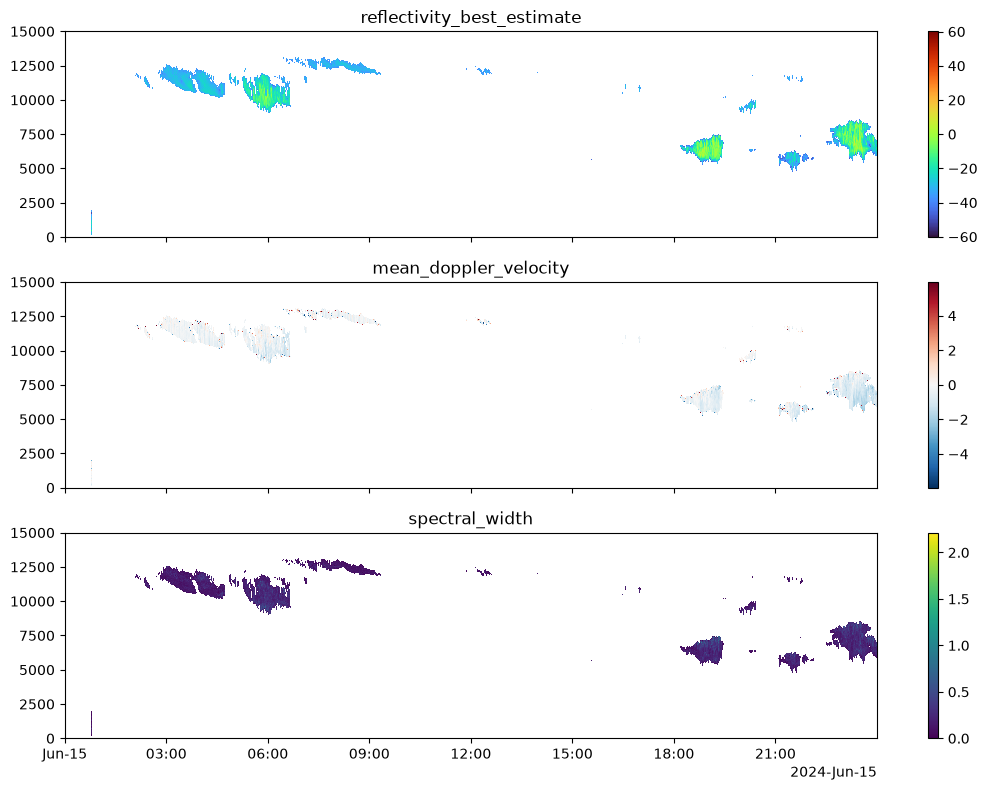

In [2]:
##Plot radar profiles##
# Create subplots for each radar variable and plot their profiles over height
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (var, cmap) in zip(axes, [("reflectivity_best_estimate", "turbo"),
                                  ("mean_doppler_velocity", "RdBu_r"), ("spectral_width", "viridis")]):
    q[var].T.plot(ax=ax, cmap=cmap, ylim=(0, 15000), add_labels=False)
    ax.set_title(var)
ds_state = q.cloud_layer_base_height.isel(layer=0) if "layer" in q.cloud_layer_base_height.dims else None
plt.tight_layout(); plt.show()